# Importations alimentaires des Comores

Notebook du projet FAOSTAT. Les données brutes sont conservées sans modification.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

ROOT_DIR = Path.cwd()
if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent
RAW_DIR = ROOT_DIR / "data" / "raw"
PROCESSED_DIR = ROOT_DIR / "data" / "processed"
FIGURES_DIR = ROOT_DIR / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Chargement

In [2]:
FILE = PROCESSED_DIR / "imports_comoros_processed.csv"
if not FILE.exists(): raise FileNotFoundError("Exécute le notebook 01.")
data = pd.read_csv(FILE)

## 2. Indicateurs généraux

In [3]:
display(data[["Quantity (t)", "Value (1000 USD)"]].describe().T)
print("Produits :", data["Item Code (CPC)"].nunique())
print("Pays fournisseurs :", data["Partner Countries"].nunique())
print("Années :", sorted(data["Year"].dropna().unique()))

,count,mean,std,min,25%,50%,75%,max
Quantity (t),"8,079.00",210.16,"2,248.22",0.00,0.25,3.00,28.00,"57,374.46"
Value (1000 USD),"8,162.00",116.54,"1,020.28",0.00,0.00,3.00,27.00,"28,728.00"


Produits : 344
Pays fournisseurs : 124
Années : [np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021)]


## 3. Produits les plus importés

,,Quantité (t)
Item Code (CPC),Item,
F0030,"Rice, paddy (rice milled equivalent)","557,227.79"
23161.03,"Rice, broken","367,959.13"
23161.02,"Rice, milled","132,934.04"
23110,Wheat and meslin flour,"104,867.55"
2351f,Raw cane or beet sugar (centrifugal only),"75,915.08"
23162,Husked rice,"56,576.25"
21121,"Meat of chickens, fresh or chilled","55,761.61"
24490,Other non-alcoholic caloric beverages,"48,917.61"
21160.01,"Edible offals and liver of chickens and guinea fowl, fresh, chilled or frozen","45,670.25"


,,Valeur (1000 USD)
Item Code (CPC),Item,
F0030,"Rice, paddy (rice milled equivalent)","228,561.00"
23161.03,"Rice, broken","155,615.00"
21121,"Meat of chickens, fresh or chilled","72,693.00"
23161.02,"Rice, milled","56,117.00"
21160.01,"Edible offals and liver of chickens and guinea fowl, fresh, chilled or frozen","54,770.00"
23110,Wheat and meslin flour,"50,225.00"
2351f,Raw cane or beet sugar (centrifugal only),"40,363.00"
24490,Other non-alcoholic caloric beverages,"29,607.00"
F1275,hydrogenated oils and fats,"25,471.00"


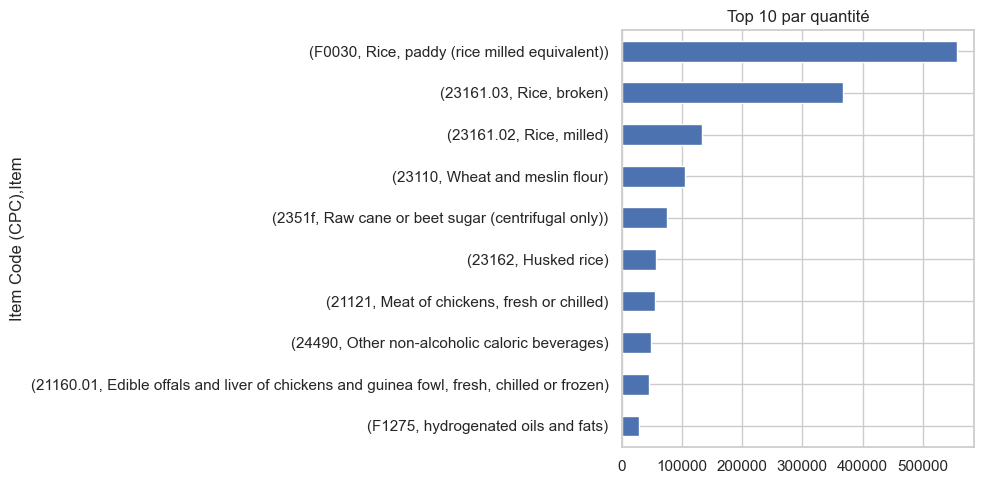

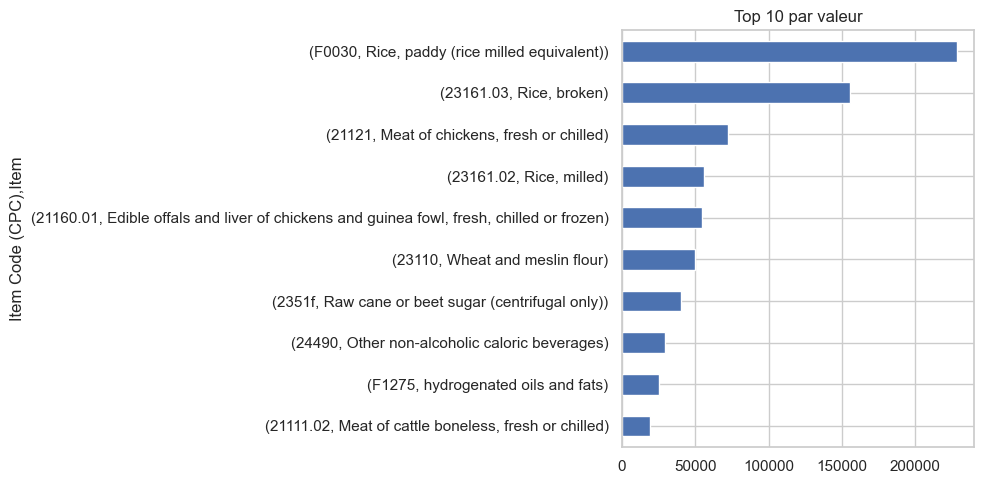

In [4]:
top_qty = data.groupby(["Item Code (CPC)", "Item"])["Quantity (t)"].sum(min_count=1).nlargest(10)
top_value = data.groupby(["Item Code (CPC)", "Item"])["Value (1000 USD)"].sum(min_count=1).nlargest(10)
display(top_qty.to_frame("Quantité (t)"))
display(top_value.to_frame("Valeur (1000 USD)"))
top_qty.sort_values().plot(kind="barh", figsize=(10,5), title="Top 10 par quantité")
plt.tight_layout(); plt.show()
top_value.sort_values().plot(kind="barh", figsize=(10,5), title="Top 10 par valeur")
plt.tight_layout(); plt.show()

## 4. Pays fournisseurs

,Value (1000 USD)
Partner Countries,
Pakistan,"354,731.00"
France,"112,865.00"
India,"77,760.00"
United Arab Emirates,"59,140.00"
South Africa,"47,260.00"
Spain,"25,811.00"
Mauritius,"22,568.00"
Poland,"19,222.00"
Viet Nam,"17,945.00"


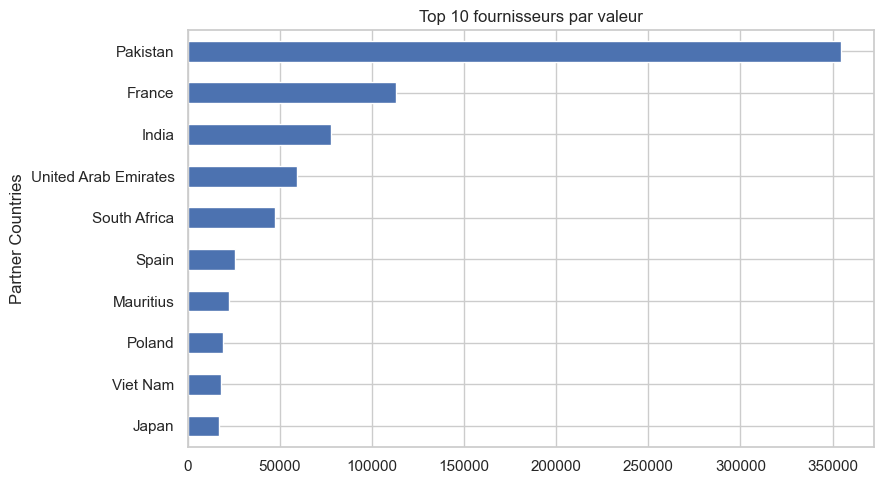

In [5]:
top_countries = data.groupby("Partner Countries")["Value (1000 USD)"].sum(min_count=1).nlargest(10)
display(top_countries.to_frame())
top_countries.sort_values().plot(kind="barh", figsize=(9,5), title="Top 10 fournisseurs par valeur")
plt.tight_layout(); plt.show()

## 5. Évolution annuelle et valeur unitaire pondérée

,Year,quantity_t,value_1000_usd
0,1995,"97,512.05","43,756.00"
1,1996,"73,206.25","32,446.00"
2,1997,"80,876.20","34,181.00"
3,1998,"39,982.00","27,401.00"
4,1999,"41,009.70","18,460.00"
5,2000,"58,779.00","20,747.00"
6,2001,"43,582.10","16,640.00"
7,2002,"55,035.00","21,548.00"
8,2016,"245,906.92","108,183.00"
9,2017,"184,630.49","112,663.00"


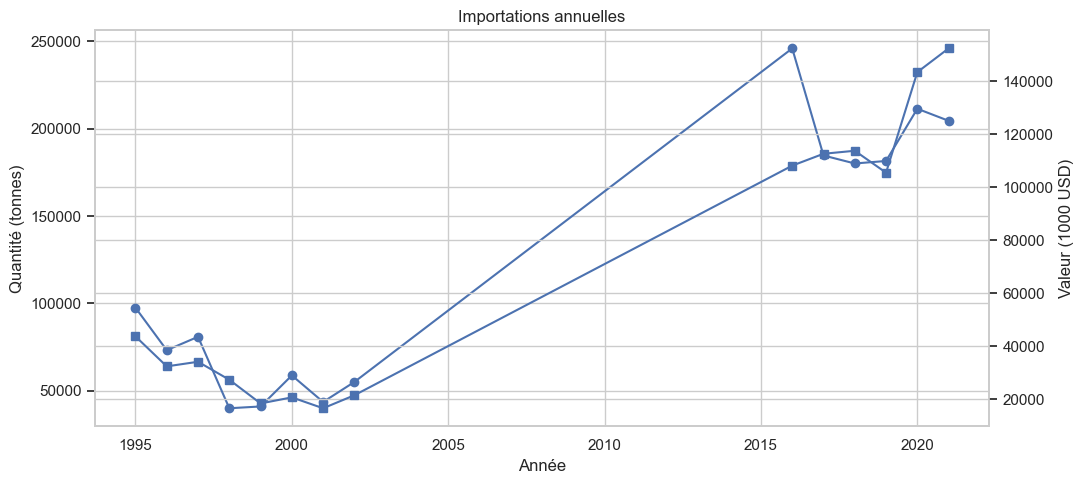

,Year,unit_value_usd_t
0,1995,448.72
1,1996,443.21
2,1997,422.63
3,1998,685.33
4,1999,450.14
5,2000,352.97
6,2001,381.81
7,2002,391.53
8,2016,439.93
9,2017,610.21


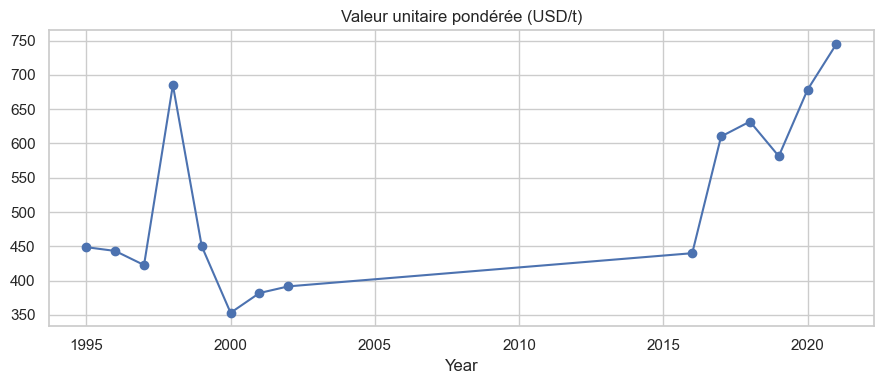

In [6]:
yearly = data.groupby("Year", as_index=False).agg(
    quantity_t=("Quantity (t)", "sum"),
    value_1000_usd=("Value (1000 USD)", "sum")
).sort_values("Year")
display(yearly)
fig, ax1 = plt.subplots(figsize=(11,5))
ax1.plot(yearly["Year"], yearly["quantity_t"], marker="o")
ax1.set_ylabel("Quantité (tonnes)"); ax1.set_xlabel("Année")
ax2 = ax1.twinx()
ax2.plot(yearly["Year"], yearly["value_1000_usd"], marker="s")
ax2.set_ylabel("Valeur (1000 USD)")
plt.title("Importations annuelles"); plt.tight_layout(); plt.show()

price = yearly[yearly["quantity_t"] > 0].copy()
price["unit_value_usd_t"] = price["value_1000_usd"] * 1000 / price["quantity_t"]
display(price[["Year", "unit_value_usd_t"]])
price.plot(x="Year", y="unit_value_usd_t", marker="o", figsize=(9,4),
           title="Valeur unitaire pondérée (USD/t)", legend=False)
plt.tight_layout(); plt.show()

## 6. Analyse par catégorie

In [7]:
category_summary = data.groupby("Product_Category", dropna=False).agg(
    quantity_t=("Quantity (t)", "sum"),
    value_1000_usd=("Value (1000 USD)", "sum"),
    products=("Item Code (CPC)", "nunique")
).sort_values("value_1000_usd", ascending=False)
display(category_summary)

,quantity_t,value_1000_usd,products
Product_Category,,,
À vérifier,"1,697,921.97","951,227.00",344
